# Naive Bayes

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix,classification_report

In [12]:
# ----------------------------
# 1. Load dataset
# ----------------------------
df = pd.read_csv("diabetes (2).csv")
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [13]:
# ----------------------------
# 2. Split into training and test sets
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101, stratify=y
)


print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")


Training set size: 537
Test set size: 231


In [14]:
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [15]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [16]:
# ----------------------------
# 3. Train Naive Bayes on training data
# ----------------------------
model = GaussianNB()
model.fit(X_train, y_train)

# ----------------------------
# 4. Evaluate on test set
# ----------------------------
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification report with custom labels
report = classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes'])
print(report)


Test Accuracy: 0.7403

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.85      0.81       150
           1       0.66      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.70       231
weighted avg       0.73      0.74      0.73       231


Confusion Matrix:
[[128  22]
 [ 38  43]]
              precision    recall  f1-score   support

 No Diabetes       0.77      0.85      0.81       150
    Diabetes       0.66      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.70       231
weighted avg       0.73      0.74      0.73       231



Text(0.5, 1.0, 'Confusion Matrix (test set)')

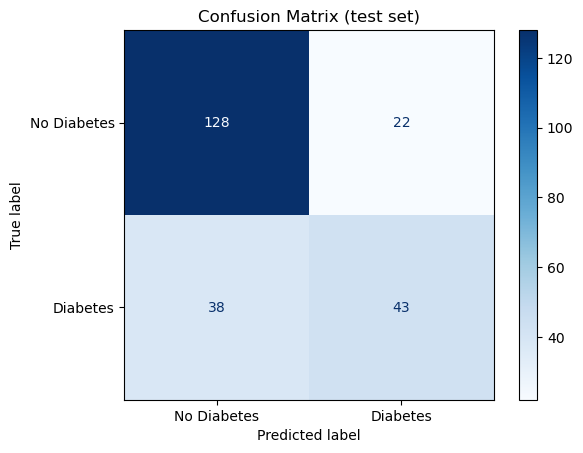

In [17]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm,display_labels=["No Diabetes","Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix (test set)")